In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the cleaned Netflix dataset
file_path = "/home/richard/Netflix_Fresh/data/cleaned/netflix_cleaned.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())


Dataset loaded successfully!
Dataset shape: (8787, 10)
Columns: ['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


In [2]:

# Count each content type
content_counts = df["type"].value_counts()

print("Netflix Content Type Counts")
print(content_counts)

print("\nTotal titles:", content_counts.sum())


Netflix Content Type Counts
type
Movie      6124
TV Show    2663
Name: count, dtype: int64

Total titles: 8787


In [3]:

# Calculate the percentage of each content type
content_percentages = (content_counts / len(df)) * 100

print("Netflix Content Type Percentages")
for content_type, percentage in content_percentages.items():
    print(f"{content_type}: {percentage:.2f}%")


Netflix Content Type Percentages
Movie: 69.69%
TV Show: 30.31%


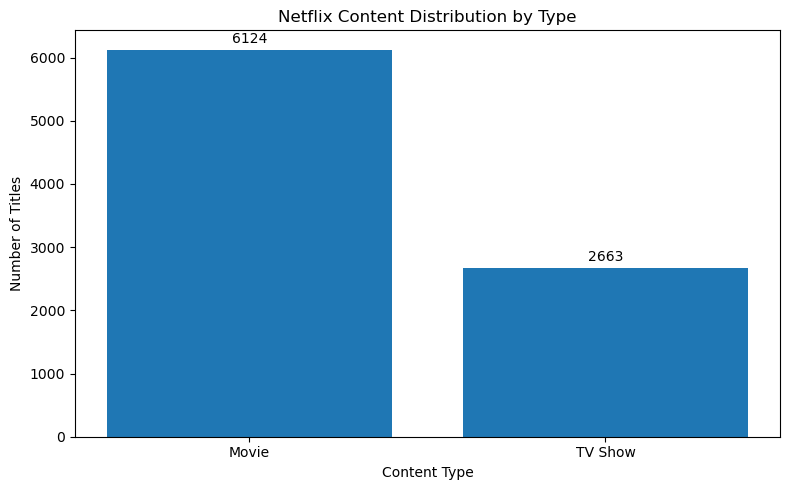

In [4]:

# Visualize content type counts
plt.figure(figsize=(8, 5))

bars = plt.bar(
    content_counts.index,
    content_counts.values
)

plt.title("Netflix Content Distribution by Type")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

# Display counts above each bar
plt.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()
plt.show()


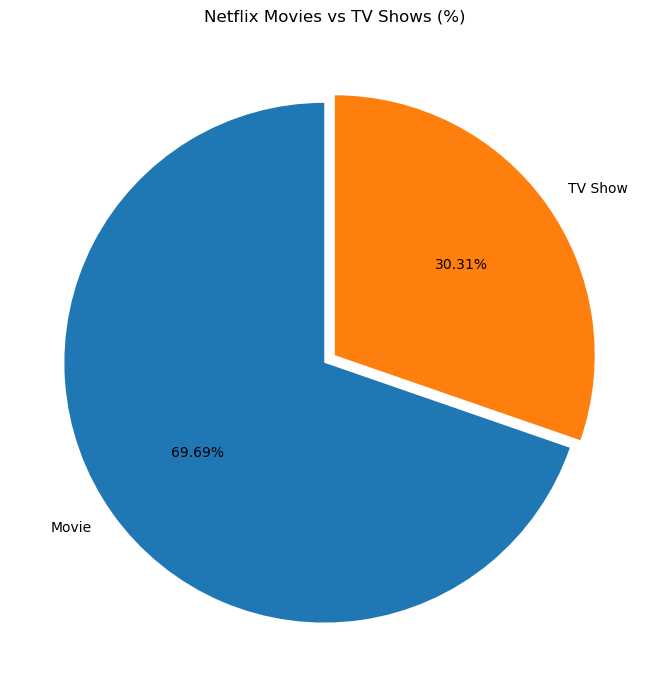

In [5]:

plt.figure(figsize=(7, 7))

plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct="%1.2f%%",
    startangle=90,
    explode=(0.05, 0)
)

plt.title("Netflix Movies vs TV Shows (%)")
plt.tight_layout()
plt.show()


## Business Insights: Netflix Content Type Analysis

The analysis of 8,787 Netflix titles shows that Movies account for 69.69% (6,124 titles), while TV Shows account for 30.31% (2,663 titles).

**Key findings:**
- Movies represent the majority of titles in the dataset.
- The number of Movies is approximately 2.3 times the number of TV Shows.
- TV Shows still make up a substantial portion of the catalog, providing opportunities to attract viewers interested in episodic content.

**Business recommendation:**

Netflix could continue maintaining a diverse content catalog while investigating audience engagement, viewing preferences, and regional demand before deciding whether to expand Movies or TV Shows.

**Conclusion:** The available dataset indicates that Netflix's catalog contains a larger number of Movies than TV Shows. This analysis measures catalog composition, not actual viewer popularity or engagement.

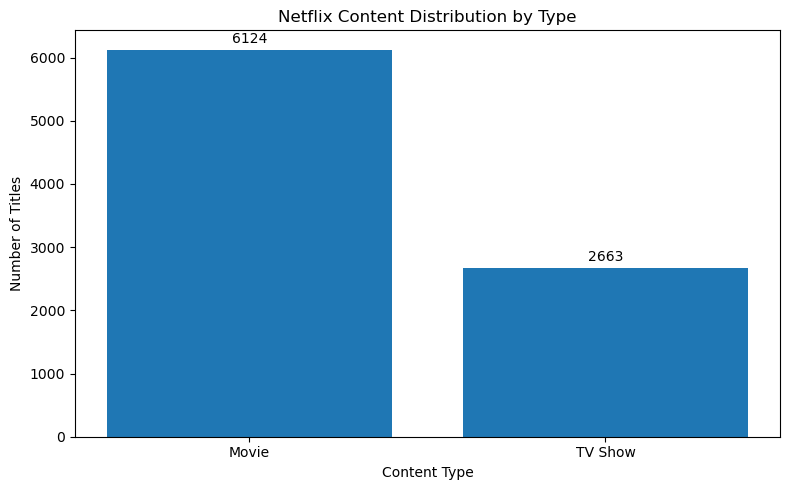

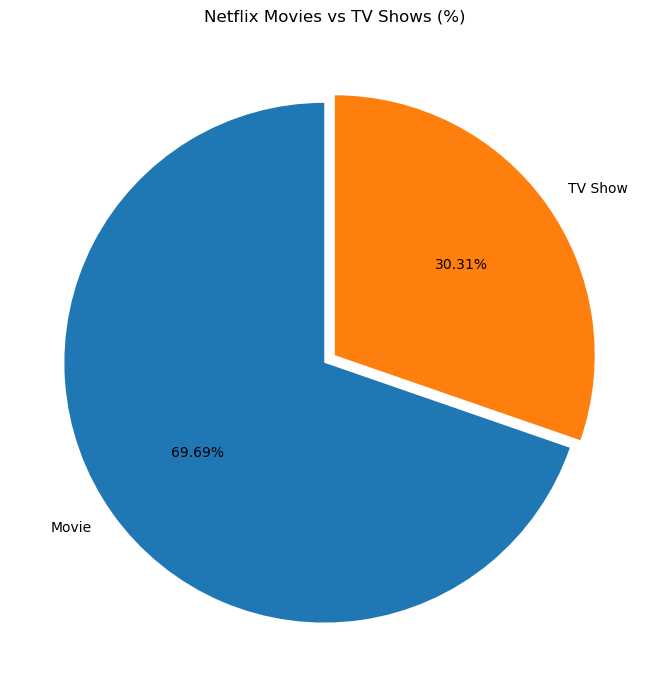

Charts saved successfully!
Output directory: /home/richard/Netflix_Fresh/outputs/figures


In [6]:

# Create the output directory
output_dir = "/home/richard/Netflix_Fresh/outputs/figures"
os.makedirs(output_dir, exist_ok=True)

# Save the bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(content_counts.index, content_counts.values)
plt.title("Netflix Content Distribution by Type")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.bar_label(bars, fmt="%d", padding=3)
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "content_type_counts.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save the pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct="%1.2f%%",
    startangle=90,
    explode=(0.05, 0)
)
plt.title("Netflix Movies vs TV Shows (%)")
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "content_type_percentages.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Charts saved successfully!")
print("Output directory:", output_dir)


In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the cleaned Netflix dataset
file_path = "/home/richard/Netflix_Fresh/data/cleaned/netflix_cleaned.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nMissing country values:", df["country"].isna().sum())


Dataset loaded successfully!
Dataset shape: (8787, 10)

Missing country values: 287


In [8]:

# Exclude records with missing country information
country_df = df.dropna(subset=["country"]).copy()

# Split records containing multiple countries
country_df["country"] = country_df["country"].str.split(", ")
country_df = country_df.explode("country")

# Count titles associated with each country
country_counts = country_df["country"].value_counts()

print("Number of unique countries:", country_counts.size)
print("\nTop 10 countries by Netflix title count:")
print(country_counts.head(10))


Number of unique countries: 85

Top 10 countries by Netflix title count:
country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


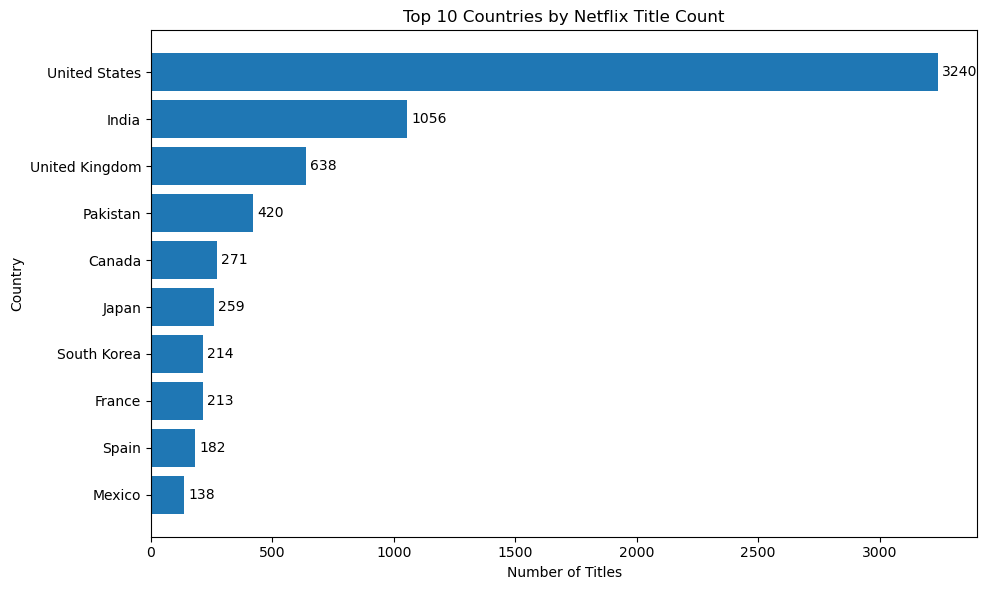

In [9]:

# Select the top 10 countries
top_10_countries = country_counts.head(10).sort_values()

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_10_countries.index,
    top_10_countries.values
)

plt.title("Top 10 Countries by Netflix Title Count")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()
plt.show()


In [10]:

# Calculate each country's share of all title-country associations
total_country_entries = country_counts.sum()

top_10_percentages = (
    country_counts.head(10) / total_country_entries
) * 100

print("Top 10 Countries by Percentage of Title-Country Associations")
print(top_10_percentages.round(2).astype(str) + "%")

print("\nTotal title-country associations:", total_country_entries)


Top 10 Countries by Percentage of Title-Country Associations
country
United States     38.12%
India             12.42%
United Kingdom     7.51%
Pakistan           4.94%
Canada             3.19%
Japan              3.05%
South Korea        2.52%
France             2.51%
Spain              2.14%
Mexico             1.62%
Name: count, dtype: object

Total title-country associations: 8500


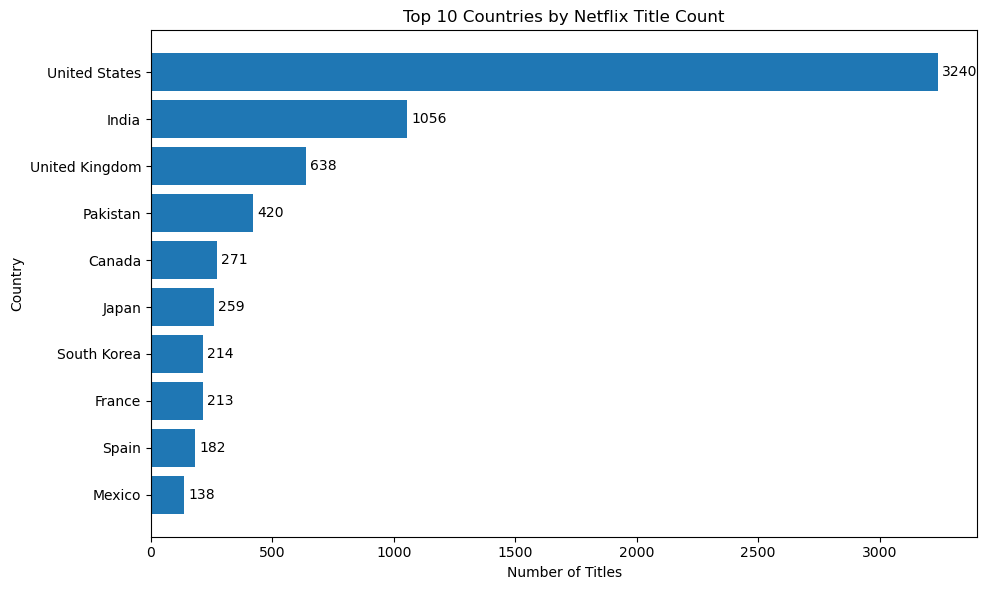

Chart saved successfully!
File location: /home/richard/Netflix_Fresh/outputs/figures/top_10_countries.png


In [11]:

# Save the top 10 countries chart
output_dir = "/home/richard/Netflix_Fresh/outputs/figures"
os.makedirs(output_dir, exist_ok=True)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_10_countries.index,
    top_10_countries.values
)

plt.title("Top 10 Countries by Netflix Title Count")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.bar_label(bars, fmt="%d", padding=3)
plt.tight_layout()

chart_path = os.path.join(
    output_dir, "top_10_countries.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")
print("File location:", chart_path)


## Business Insights: Country-Wise Netflix Content Analysis

The analysis identified 85 unique countries represented in the Netflix dataset, with 287 titles having missing country information. After excluding records with missing country values and separating multi-country entries, 8,500 title-country associations remained.

### Key Findings

- **United States:** Leads with 3,240 title-country associations (38.12%).
- **India:** Ranks second with 1,056 associations (12.42%).
- **United Kingdom:** Ranks third with 638 associations (7.51%).
- **Other represented countries:** Pakistan, Canada, Japan, South Korea, France, Spain, and Mexico complete the top 10.

### Business Recommendations

1. Continue evaluating content from major contributing countries, particularly the United States and India.
2. Explore opportunities to develop or acquire content from a wider range of countries to support regional diversity.
3. Investigate country-specific viewing data before making investment decisions, since catalog counts alone do not indicate audience demand or profitability.

### Conclusion

The dataset shows that Netflix's catalog is strongly represented by content associated with the United States and India. Country counts provide a useful overview of catalog distribution, but additional viewing and engagement data would be needed to assess content performance.

**Methodological note:** Titles associated with multiple countries were counted once for each associated country. Therefore, the country counts and percentages represent title-country associations, not unique Netflix titles.

In [12]:

# Export country rankings
output_dir = "/home/richard/Netflix_Fresh/outputs"
os.makedirs(output_dir, exist_ok=True)

country_results = country_counts.rename_axis(
    "country"
).reset_index(name="title_country_associations")

country_results.to_csv(
    os.path.join(output_dir, "country_analysis.csv"),
    index=False
)

print("Country analysis exported successfully!")
print("Total countries:", len(country_results))
print("Saved to:", os.path.join(output_dir, "country_analysis.csv"))


Country analysis exported successfully!
Total countries: 85
Saved to: /home/richard/Netflix_Fresh/outputs/country_analysis.csv
